In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare
from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEARCH_SPACE = {
    "cooldown_long": [30, 60, 90],
    "cooldown_short": [7, 14, 30],
}

In [4]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experiment": {"minimum_loss": 1.1, "cooldown_long": 60.0, "cooldown_short": 14.0}
}

In [5]:
df_prices = pd.read_csv("data/test_stocks.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,AAPL,MSFT,NVDA,AMZN,BRK-B,JPM,WMT,LLY,XOM,UNH,...,DIS,INTU,TXN,CAT,QCOM,AMGN,VZ,RTX,SPGI,NVO
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,0.999442,58.281250,0.097526,4.468750,35.299999,48.583332,22.270832,65.562500,39.156250,6.718750,...,29.471687,30.125000,51.437500,24.312500,89.656250,62.937500,53.903156,19.666456,29.218750,1.345000
2000-01-04,0.915179,56.312500,0.094922,4.096875,34.080002,47.250000,21.437500,63.500000,38.406250,6.632813,...,31.198063,30.437500,49.250000,24.000000,81.031250,58.125000,52.160721,18.860132,27.875000,1.338750
2000-01-05,0.928571,56.906250,0.091797,3.487500,34.639999,46.958332,21.000000,64.312500,40.500000,6.617188,...,32.492844,39.218750,48.062500,24.562500,78.218750,60.125000,53.903156,18.486469,27.500000,1.313750
2000-01-06,0.848214,55.000000,0.085807,3.278125,36.080002,47.625000,21.229168,66.187500,42.593750,6.859375,...,31.198063,35.000000,46.750000,25.812500,70.031250,61.125000,53.284874,19.371460,26.750000,1.335000
2000-01-07,0.888393,55.718750,0.087240,3.478125,36.400002,48.500000,22.833332,71.062500,42.468750,7.664063,...,30.704813,36.781250,47.000000,26.656250,75.000000,68.000000,52.891418,20.138453,27.000000,1.370000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-08,301.540009,411.739990,208.639999,245.220001,487.000000,311.109985,119.830002,1149.150024,151.750000,406.570007,...,98.870003,305.510010,290.899994,915.640015,217.770004,345.730011,45.439999,178.660004,417.089996,41.020000
2026-06-09,290.549988,403.410004,208.190002,244.190002,487.769989,312.700012,118.879997,1144.680054,148.910004,413.000000,...,99.330002,293.779999,288.630005,914.700012,205.419998,344.570007,45.779999,181.559998,424.820007,42.189999
2026-06-10,291.579987,397.359985,200.419998,238.000000,483.679993,309.140015,120.589996,1136.369995,150.619995,407.459991,...,98.610001,284.220001,282.010010,856.159973,191.199997,337.730011,46.950001,177.410004,426.380005,42.810001


# SEARCH

In [6]:
history_search = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 5,
    )

100%|██████████| 9/9 [11:47<00:00, 78.66s/it]


In [7]:
history_search

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,cooldown_long=30_cooldown_short=7,CVX,3395,379,4091,3175,4470,98,64.197846,1,-36,-1398,76.666667,24,1
1,cooldown_long=30_cooldown_short=7,WMT,3405,0,3843,3405,3843,36,16.966260,0,-17,-400,26.000000,-2,1
2,cooldown_long=30_cooldown_short=7,NVO,3405,3020,4355,1934,7376,82,10.972756,8,-20,-666,208.000000,78,1
3,cooldown_long=30_cooldown_short=7,GE,3385,1206,11241,2860,12448,78,74.182364,3,-47,-2734,59.428571,43,1
4,cooldown_long=30_cooldown_short=7,AMZN,3385,3856,3885,1418,7741,72,3.927886,10,-36,-1181,164.500000,78,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,cooldown_long=90_cooldown_short=30,JPM,3395,2078,3751,2072,5830,91,94.176639,7,-31,-1326,241.000000,38,100
8996,cooldown_long=90_cooldown_short=30,VZ,3405,277,4372,3221,4649,89,40.151430,1,-10,-352,47.333333,26,100
8997,cooldown_long=90_cooldown_short=30,COST,3405,407,6278,3132,6685,97,149.139021,1,-18,-902,60.333333,24,100
8998,cooldown_long=90_cooldown_short=30,CSCO,3375,945,4128,2743,5074,68,22.759827,2,-20,-735,54.000000,11,100


In [8]:
search_res = history_search.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

search_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
cooldown_long=30_cooldown_short=30,30.45,-31.66,-1277.14,4573.60,926.44,3403.72,5500.35,4854.50,4027.75,5928.25
cooldown_long=60_cooldown_short=7,30.37,-31.27,-1362.86,4946.87,828.88,3402.48,5776.08,4897.50,4069.50,6017.25
cooldown_long=30_cooldown_short=7,29.12,-31.32,-1165.82,4288.79,1050.33,3405.31,5339.42,4861.50,4007.75,5856.00
cooldown_long=60_cooldown_short=30,29.12,-32.42,-1468.91,5001.99,745.17,3405.94,5747.51,4899.00,4059.50,6088.25
cooldown_long=90_cooldown_short=7,27.84,-32.65,-1432.24,5236.11,591.08,3404.39,5827.48,4774.50,3989.00,6065.00
cooldown_long=30_cooldown_short=14,27.81,-32.60,-1211.00,4382.97,976.91,3407.82,5360.21,4793.00,3975.00,5900.00
cooldown_long=90_cooldown_short=14,27.39,-33.15,-1384.45,4972.17,579.47,3408.45,5551.93,4775.00,3990.00,5918.50
cooldown_long=90_cooldown_short=30,27.24,-32.06,-1355.76,5027.29,573.43,3403.09,5601.04,4862.50,4002.00,6219.25
cooldown_long=60_cooldown_short=14,26.92,-32.56,-1327.09,4824.35,695.09,3405.44,5519.75,4805.50,3997.50,5979.25


# COMPARE

In [ ]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 5,
)

 25%|██▌       | 1/4 [01:05<03:15, 65.31s/it]

In [ ]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,BuyHold,VET,1554,0,3329,1554,3329,27,0.026018,0,-54,-1287,70.333333,-18,1
1,BuyHold,USDT,1554,0,1553,1554,1553,37,1.000051,0,0,-2,0.000000,0,1
2,BuyHold,NEO,1544,0,970,1544,970,58,9.623913,0,-79,-2669,30.000000,4,1
3,BuyHold,MKR,1544,0,2534,1544,2534,39,1204.880602,0,-53,-2497,65.800000,-15,1
4,BuyHold,OMG,1544,0,365,1544,365,37,2.008323,0,-87,-2112,292.000000,-15,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experiment,MKR,2682,901,6846,2186,7748,29,1171.716746,25,-59,-921,0.000000,-23,100
3996,Experiment,MKR,2494,4012,1438,1082,5450,46,1200.210229,23,-54,-1826,266.000000,-4,100
3997,Experiment,BCH,2237,1512,2553,1259,4066,59,207.982110,18,-51,-1880,120.500000,79,100
3998,Experiment,ONT,2831,271,2300,2742,2572,21,0.286566,27,-46,-1032,0.000000,-17,100


In [ ]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
Default,41.99,-40.20,-732.42,1203.23,1193.43,1682.79,2397.08,2109.50,1623.25,2764.75
Experiment,41.36,-42.01,-1155.06,1851.89,1644.58,2523.14,3496.92,3200.00,2557.50,4018.75
NoConfirm,36.20,-40.42,-698.28,1151.63,1150.95,1683.97,2302.90,2175.00,1565.75,2822.50
BuyHold,4.67,-62.24,-2376.11,1933.36,0.00,1548.37,1933.36,1511.00,1020.00,2266.00


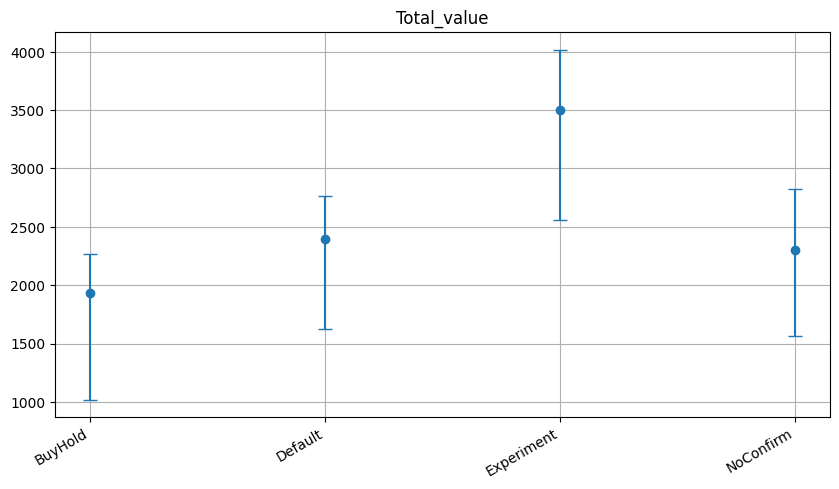

In [ ]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

means = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    means.index,
    means.values,
    yerr=[means - low, high - means],
    fmt="o",
    capsize=5,
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()